
# Optimizing Travel Costs for Dental Tourism

## 1. Introduction

International patients travel to Bulgaria for dental treatment. Their travel expenses may include flights, hotel accommodation, and airport transfers.

This project aims to develop a Python model that compares travel options and identifies the lowest-cost feasible combination.

## 2. Project Objectives

- Calculate total travel costs.
- Compare flight, hotel, and transfer options.
- Consider the required length of stay.
- Find the cheapest feasible travel plan.
- Analyze how price changes affect total costs.

## 3. Data and Assumptions

The project initially uses illustrative data created for educational purposes. The prices do not represent actual market quotations.

The analysis focuses on travel expenses and excludes the cost of dental treatment.


In [2]:

# Example travel prices in euros (EUR)

flights = {
    "Flight A": 180,
    "Flight B": 220,
    "Flight C": 200
}

hotel_prices_per_night = {
    "Hotel A": 60,
    "Hotel B": 80,
    "Hotel C": 50
}

transfer_prices = {
    "Transfer A": 40,
    "Transfer B": 60
}

# Required length of stay
nights = 3

print("Available flights:", flights)
print("Hotel prices per night:", hotel_prices_per_night)
print("Transfer prices:", transfer_prices)
print("Required nights:", nights)


Available flights: {'Flight A': 180, 'Flight B': 220, 'Flight C': 200}
Hotel prices per night: {'Hotel A': 60, 'Hotel B': 80, 'Hotel C': 50}
Transfer prices: {'Transfer A': 40, 'Transfer B': 60}
Required nights: 3


In [3]:

# Select one travel option

flight_price = flights["Flight A"]
hotel_price = hotel_prices_per_night["Hotel A"]
transfer_price = transfer_prices["Transfer A"]

# Calculate the total travel cost
total_cost = (
    flight_price
    + nights * hotel_price
    + transfer_price
)

print(f"Total travel cost: €{total_cost}")


Total travel cost: €400


In [4]:

def calculate_total_cost(flight_price, hotel_price, transfer_price, nights):
    total = flight_price + hotel_price * nights + transfer_price
    return total


# Test the function
example_cost = calculate_total_cost(180, 60, 40, 3)

print(f"Example total cost: €{example_cost}")


Example total cost: €400


In [5]:

# Compare all possible travel combinations

best_option = None
lowest_cost = float("inf")

for flight_name, flight_price in flights.items():
    for hotel_name, hotel_price in hotel_prices_per_night.items():
        for transfer_name, transfer_price in transfer_prices.items():

            total = calculate_total_cost(
                flight_price,
                hotel_price,
                transfer_price,
                nights
            )

            if total < lowest_cost:
                lowest_cost = total
                best_option = (
                    flight_name,
                    hotel_name,
                    transfer_name
                )

print("Cheapest option:")
print("Flight:", best_option[0])
print("Hotel:", best_option[1])
print("Transfer:", best_option[2])
print(f"Total cost: €{lowest_cost}")


Cheapest option:
Flight: Flight A
Hotel: Hotel C
Transfer: Transfer A
Total cost: €370



## 4. Mathematical Model

The total travel cost is calculated using the following formula:

$$
C_{\text{total}} = C_{\text{flight}} + n \cdot C_{\text{hotel}} + C_{\text{transfer}}
$$

Where:

- $C_{\text{flight}}$ is the price of the flight.
- $n$ is the number of hotel nights.
- $C_{\text{hotel}}$ is the price per hotel night.
- $C_{\text{transfer}}$ is the transfer cost.

The objective is to minimize the total travel cost by selecting one flight, one hotel, and one transfer option.

Mathematically, this can be written as:

$$
C_{\min} = \min_{i,j,k}
\left(
F_i + nH_j + T_k
\right)
$$

where $F_i$, $H_j$, and $T_k$ represent the prices of the available flight, hotel, and transfer options.


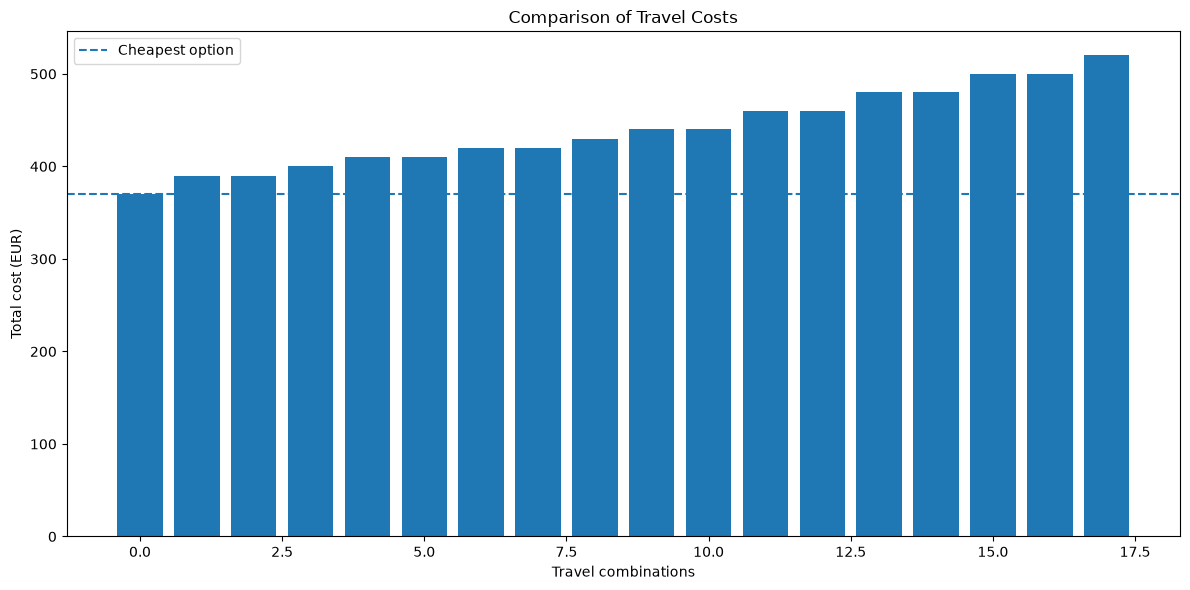

Number of combinations: 18
Cheapest cost: 370
Most expensive cost: 520


In [6]:

import matplotlib.pyplot as plt

# Store the total cost of each combination
all_costs = []

for flight_name, flight_price in flights.items():
    for hotel_name, hotel_price in hotel_prices_per_night.items():
        for transfer_name, transfer_price in transfer_prices.items():
            total = calculate_total_cost(
                flight_price,
                hotel_price,
                transfer_price,
                nights
            )

            label = f"{flight_name}, {hotel_name}, {transfer_name}"
            all_costs.append((label, total))

# Sort combinations from cheapest to most expensive
all_costs.sort(key=lambda item: item[1])

# Prepare data for the chart
labels = [item[0] for item in all_costs]
costs = [item[1] for item in all_costs]

plt.figure(figsize=(12, 6))
plt.bar(range(len(costs)), costs)
plt.axhline(lowest_cost, linestyle="--", label="Cheapest option")
plt.xlabel("Travel combinations")
plt.ylabel("Total cost (EUR)")
plt.title("Comparison of Travel Costs")
plt.legend()
plt.tight_layout()
plt.show()

print("Number of combinations:", len(all_costs))
print("Cheapest cost:", lowest_cost)
print("Most expensive cost:", max(costs))


In [7]:

# Calculate potential savings

most_expensive_cost = max(costs)
cheapest_cost = min(costs)

savings = most_expensive_cost - cheapest_cost
savings_percentage = (savings / most_expensive_cost) * 100

print(f"Cheapest option: €{cheapest_cost}")
print(f"Most expensive option: €{most_expensive_cost}")
print(f"Potential savings: €{savings}")
print(f"Potential savings percentage: {savings_percentage:.2f}%")


Cheapest option: €370
Most expensive option: €520
Potential savings: €150
Potential savings percentage: 28.85%


In [8]:
# Test the cost calculation function

assert calculate_total_cost(180, 60, 40, 3) == 400
assert calculate_total_cost(220, 50, 40, 3) == 410
assert calculate_total_cost(200, 80, 60, 3) == 500

print("All cost calculation tests passed!")

All cost calculation tests passed!
